# Forest Cover Analysis in India

**EDAV Project**

This project analyzes historical forest-cover data across Indian states and union territories, explores changes in reported forest cover over different years, compares state-level patterns, and visualizes the findings using Python.

- **Dataset:** Forest coverage data from 1987–2013, containing state/UT-level values and national summaries.
- **Data Analysis:** Cleans missing and incorrectly formatted values, performs statistical calculations, ranks states, and examines changes across reporting years.
- **Visualization:** Uses line charts, bar charts, histograms, scatter plots, box plots, violin plots, and heatmaps to identify patterns and compare forest-cover values.
- **Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, and optionally GeoPandas for geographical visualization.

## 1. Import Libraries

In [ ]:
# importing labraries
import os
import pandas as pd
from google.colab import files
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load Dataset

In [ ]:
# Try the project-folder path first. If not found, ask you to upload the Excel file.
candidate_paths = [
    "data/Forest Coverage (1987-2013).xlsx",
    "./Forest Coverage (1987-2013).xlsx",
    "/content/Forest Coverage (1987-2013).xlsx",
]

excel_path = next((p for p in candidate_paths if os.path.exists(p)), None)

if excel_path is None:
    try:
        from google.colab import files
        uploaded = files.upload()
        excel_path = next(
            (name for name in uploaded if name.lower().endswith((".xlsx", ".xls"))),
            None
        )
    except ImportError:
        pass

if excel_path is None:
    raise FileNotFoundError(
        "Excel file not found. Place 'Forest Coverage (1987-2013).xlsx' "
        "in the data folder or upload it in Colab."
    )

raw_data = pd.read_excel(excel_path)
print("Loaded:", excel_path)
print("Shape:", raw_data.shape)
display(raw_data)

Loaded: ./Forest Coverage (1987-2013).xlsx
Shape: (37, 14)


,State/UTs,1987,1989,1991,1993,1995,1997,1999,2001,2003,2005,2007,2011,2013
0,Andhra Pradesh,"49,573","47,290","47,290","47,256","47,112","43,290","44,229","44,637","44,419","44,372","45,102","46,389","46,116"
1,Arunachal Pradesh,"64,132","69,002","68,757","68,661","68,621","68,602","68,847","68,045","68,019","67,777","67,353","67,410","67,321"
2,Assam,"25,160","24,832","24,751","24,508","24,061","23,824","23,688","27,714","27,826","27,645","27,692","27,673","27,671"
3,Bihar,"28,482","26,668","26,668","26,587","26,561","4,832","4,830","5,720","5,558","5,579","6,804","6,845","7,291"
4,Chhattisgarh,-,-,-,-,-,"56,435","56,693","56,448","55,998","55,863","55,870","55,674","55,621"
5,Delhi,15,22,22,22,26,26,88,111,170,176,177,176,179.81
6,Goa,"1,240","1,255","1,255","1,250","1,250","1,252","1,251","2,095","2,156","2,164","2,151","2,219","2,219"
7,Gujarat,"11,991","11,921","11,907","12,044","12,320","12,578","12,965","15,152","14,946","14,715","14,620","14,619","14,653"
8,Haryana,513,513,513,513,603,604,964,"1,754","1,517","1,587","1,594","1,608","1,586"
9,Himachal Pradesh,"12,480","12,480","12,480","12,502","12,501","12,521","13,082","14,360","14,353","14,369","14,668","14,679","14,683"


## 3. View Dataset

In [ ]:
print("Column names:")
print(raw_data.columns.tolist())

print("\nShape (rows, columns):", raw_data.shape)
print("\nData types and non-null counts:")
raw_data.info()

print("\nFirst five rows:")
display(raw_data.head())

print("\nLast five rows (useful for spotting summary rows):")
display(raw_data.tail())

print("\nDescriptive summary:")
display(raw_data.describe(include="all"))

Column names:
['State/UTs', '1987', '1989', '1991', '1993', '1995', '1997', '1999', '2001', '2003', '2005', '2007', '2011', '2013']

Shape (rows, columns): (37, 14)

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37 entries, 0 to 36
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   State/UTs  37 non-null     object
 1   1987       37 non-null     object
 2   1989       37 non-null     object
 3   1991       37 non-null     object
 4   1993       37 non-null     object
 5   1995       37 non-null     object
 6   1997       37 non-null     object
 7   1999       37 non-null     object
 8   2001       37 non-null     object
 9   2003       37 non-null     object
 10  2005       37 non-null     object
 11  2007       37 non-null     object
 12  2011       37 non-null     object
 13  2013       37 non-null     object
dtypes: object(14)
memory usage: 4.2+ KB

First five rows:


,State/UTs,1987,1989,1991,1993,1995,1997,1999,2001,2003,2005,2007,2011,2013
0,Andhra Pradesh,"49,573","47,290","47,290","47,256","47,112","43,290","44,229","44,637","44,419","44,372","45,102","46,389","46,116"
1,Arunachal Pradesh,"64,132","69,002","68,757","68,661","68,621","68,602","68,847","68,045","68,019","67,777","67,353","67,410","67,321"
2,Assam,"25,160","24,832","24,751","24,508","24,061","23,824","23,688","27,714","27,826","27,645","27,692","27,673","27,671"
3,Bihar,"28,482","26,668","26,668","26,587","26,561","4,832","4,830","5,720","5,558","5,579","6,804","6,845","7,291"
4,Chhattisgarh,-,-,-,-,-,"56,435","56,693","56,448","55,998","55,863","55,870","55,674","55,621"



Last five rows (useful for spotting summary rows):


,State/UTs,1987,1989,1991,1993,1995,1997,1999,2001,2003,2005,2007,2011,2013
32,Daman & Diu,0,0,0,0,0,0,0,6,8,8,6,6,9.27
33,Lakshadweep,0,0,0,0,0,0,0,27,23,25,26,27,27.06
34,Puducherry,0,0,0,0,0,0,0,36,40,42,44,50,50.06
35,Grand Total,"6,40,819","6,38,804","6,39,364","6,39,386","6,38,879","6,33,397","6,37,293","6,75,538","6,78,333","6,77,088","6,90,899","6,92,027","6,97,898"
36,Per cent,19.49,19.43,19.45,19.45,19.43,19.27,19.39,20.55,20.64,20.60,21.02,21.05,21.23



Descriptive summary:


,State/UTs,1987,1989,1991,1993,1995,1997,1999,2001,2003,2005,2007,2011,2013
count,37,37,37,37,37,37,37,37,37,37,37,37,37,37
unique,37,33,33,33,33,33,35,35,37,37,37,37,37,37
top,Andhra Pradesh,-,-,-,-,-,0,0,"44,637","44,419","44,372","45,102","46,389","46,116"
freq,1,3,3,3,3,3,3,3,1,1,1,1,1,1


## 4. Data Cleaning

In [ ]:
# Work on a copy; preserve raw_data unchanged.
data = raw_data.copy()
data.columns = [str(c).strip() for c in data.columns]

state_col = "State/UTs"
if state_col not in data.columns:
    raise KeyError(f"Expected '{state_col}' column. Actual columns: {data.columns.tolist()}")

# Identify year columns (Excel may read year headings as strings or integers).
year_cols_original = [c for c in data.columns if str(c).strip().isdigit()]
year_cols_original = sorted(year_cols_original, key=lambda c: int(str(c)))

# Separate summary rows before state-level cleaning.
state_labels = data[state_col].astype("string").str.strip()
summary_mask = state_labels.str.casefold().isin(["grand total", "per cent"])
summary_data = data.loc[summary_mask].copy()
forest_wide = data.loc[~summary_mask].copy()

# Standardize state names and convert values like '49,573' to numeric.
forest_wide[state_col] = forest_wide[state_col].astype("string").str.strip()
for col in year_cols_original:
    forest_wide[col] = pd.to_numeric(
        forest_wide[col].astype("string")
        .str.replace(",", "", regex=False)
        .str.strip()
        .replace("-", pd.NA),
        errors="coerce"
    )

# Use integer year labels after conversion for easier analysis.
rename_years = {c: int(str(c)) for c in year_cols_original}
forest_wide = forest_wide.rename(columns=rename_years)
years = [int(str(c)) for c in year_cols_original]

# Remove exact duplicate state rows only if they exist.
duplicates_before = int(forest_wide.duplicated().sum())
forest_wide = forest_wide.drop_duplicates().reset_index(drop=True)

print("Raw shape:", raw_data.shape)
print("State/UT rows after excluding summary rows:", forest_wide.shape[0])
print("Year columns:", years)
print("Exact duplicate rows removed:", duplicates_before)
print("Missing measurements by year:")
display(forest_wide[years].isna().sum().rename("missing_count").to_frame())
display(forest_wide.head())

Raw shape: (37, 14)
State/UT rows after excluding summary rows: 35
Year columns: [1987, 1989, 1991, 1993, 1995, 1997, 1999, 2001, 2003, 2005, 2007, 2011, 2013]
Exact duplicate rows removed: 0
Missing measurements by year:


,missing_count
1987,3
1989,3
1991,3
1993,3
1995,3
1997,0
1999,0
2001,0
2003,0
2005,0


,State/UTs,1987,1989,1991,1993,1995,1997,1999,2001,2003,2005,2007,2011,2013
0,Andhra Pradesh,49573,47290,47290,47256,47112,43290,44229,44637,44419,44372,45102,46389,46116.0
1,Arunachal Pradesh,64132,69002,68757,68661,68621,68602,68847,68045,68019,67777,67353,67410,67321.0
2,Assam,25160,24832,24751,24508,24061,23824,23688,27714,27826,27645,27692,27673,27671.0
3,Bihar,28482,26668,26668,26587,26561,4832,4830,5720,5558,5579,6804,6845,7291.0
4,Chhattisgarh,<NA>,<NA>,<NA>,<NA>,<NA>,56435,56693,56448,55998,55863,55870,55674,55621.0


### Missing Values

In [ ]:
# Missing values count
print("Total missing year/state measurements:", int(forest_wide[years].isna().sum().sum()))

# dropna example: complete cases for a chosen pair of years only.
complete_2011_2013 = forest_wide.dropna(subset=[2011, 2013])
print("Rows with both 2011 and 2013 values:", len(complete_2011_2013))

# fillna example on a small demonstration copy (NOT the analysis dataset).
demo = forest_wide[[state_col, 2011, 2013]].head(5).copy()
demo_filled = demo.fillna({2011: demo[2011].median(), 2013: demo[2013].median()})
print("Demonstration of fillna on a copy:")
display(demo_filled)

# replace example: turn a dash into NA in the original-shaped raw data copy.
replacement_demo = raw_data[[state_col] + year_cols_original].copy()
replacement_demo = replacement_demo.replace("-", pd.NA)
print("Dashes replaced in a demonstration copy; not treated as zero.")

Total missing year/state measurements: 15
Rows with both 2011 and 2013 values: 35
Demonstration of fillna on a copy:


,State/UTs,2011,2013
0,Andhra Pradesh,46389,46116.0
1,Arunachal Pradesh,67410,67321.0
2,Assam,27673,27671.0
3,Bihar,6845,7291.0
4,Chhattisgarh,55674,55621.0


Dashes replaced in a demonstration copy; not treated as zero.


## 5. Prepare Data

In [ ]:
# Extract the national summary rows separately; these are not state observations.
summary_data = summary_data.copy()
summary_data[state_col] = summary_data[state_col].astype("string").str.strip()

def parse_number(value):
    return pd.to_numeric(str(value).replace(",", "").strip(), errors="coerce")

total_row = summary_data[
    summary_data[state_col].str.casefold().eq("grand total")
]
percent_row = summary_data[
    summary_data[state_col].str.casefold().eq("per cent")
]

if not total_row.empty:
    national_total = pd.Series(
        {int(str(c)): parse_number(total_row.iloc[0][c]) for c in year_cols_original}
    ).sort_index()
else:
    national_total = pd.Series(dtype=float)

if not percent_row.empty:
    national_percent = pd.Series(
        {int(str(c)): parse_number(percent_row.iloc[0][c]) for c in year_cols_original}
    ).sort_index()
else:
    national_percent = pd.Series(dtype=float)

# Wide-to-long transformation: one row per state/UT and reporting year.
long_data = forest_wide.melt(
    id_vars=[state_col],
    value_vars=years,
    var_name="year",
    value_name="forest_cover"
).rename(columns={state_col: "state"})

long_data["year"] = pd.to_numeric(long_data["year"], errors="coerce").astype("Int64")
long_data["forest_cover"] = pd.to_numeric(long_data["forest_cover"], errors="coerce")
long_data["date"] = pd.to_datetime(long_data["year"].astype(str) + "-01-01", errors="coerce")

print("Long-format shape:", long_data.shape)
display(long_data.head())
print("National total series:")
display(national_total.rename("reported_total").to_frame())
print("National percentage series:")
display(national_percent.rename("reported_percent").to_frame())

Long-format shape: (455, 4)


,state,year,forest_cover,date
0,Andhra Pradesh,1987,49573.0,1987-01-01
1,Arunachal Pradesh,1987,64132.0,1987-01-01
2,Assam,1987,25160.0,1987-01-01
3,Bihar,1987,28482.0,1987-01-01
4,Chhattisgarh,1987,<NA>,1987-01-01


National total series:


,reported_total
1987,640819
1989,638804
1991,639364
1993,639386
1995,638879
1997,633397
1999,637293
2001,675538
2003,678333
2005,677088


National percentage series:


,reported_percent
1987,19.49
1989,19.43
1991,19.45
1993,19.45
1995,19.43
1997,19.27
1999,19.39
2001,20.55
2003,20.64
2005,20.60


## 6. NumPy Operations

In [ ]:
# 1D array: all non-missing state/year observations.
values_1d = long_data["forest_cover"].dropna().to_numpy(dtype=float)

# 2D array: state rows x year columns (may contain NaN).
values_2d = forest_wide[years].to_numpy(dtype=float)

# 3D array: reshape a small real-data slice for demonstrating dimensions.
# First 4 states x first 3 years = 12 values, reshaped to (2, 2, 3).
values_3d = values_2d[:4, :3].reshape(2, 2, 3)

print("1D shape:", values_1d.shape)
print("2D shape:", values_2d.shape)
print("3D shape:", values_3d.shape)
print("First 5 values:", values_1d[:5])

# Indexing and slicing
print("First observation:", values_1d[0])
print("First five observations:", values_1d[:5])

# Arithmetic and broadcasting
print("First five values doubled:", (values_1d[:5] * 2))
print("First five values + 10:", (values_1d[:5] + 10))

# Broadcasting example: add a per-year vector to each row of the matrix.
column_means = np.nanmean(values_2d, axis=0)
centered = values_2d - column_means
print("Per-year means shape:", column_means.shape)
print("Centered matrix shape:", centered.shape)

1D shape: (440,)
2D shape: (35, 13)
3D shape: (2, 2, 3)
First 5 values: [4.9573e+04 6.4132e+04 2.5160e+04 2.8482e+04 1.5000e+01]
First observation: 49573.0
First five observations: [4.9573e+04 6.4132e+04 2.5160e+04 2.8482e+04 1.5000e+01]
First five values doubled: [9.91460e+04 1.28264e+05 5.03200e+04 5.69640e+04 3.00000e+01]
First five values + 10: [4.9583e+04 6.4142e+04 2.5170e+04 2.8492e+04 2.5000e+01]
Per-year means shape: (13,)
Centered matrix shape: (35, 13)


## 7. Advanced NumPy

In [ ]:
print("Transpose shape:", values_2d.T.shape)
print("Small reshaped array shape:", values_3d.reshape(3, 4).shape)

# Reproducible random sample from actual reported observations.
rng = np.random.default_rng(42)
sample_n = min(5, len(values_1d))
print("Random sample of observed values:", rng.choice(values_1d, size=sample_n, replace=False))

# Aggregate functions
print("Minimum:", np.nanmin(values_2d))
print("Maximum:", np.nanmax(values_2d))
print("Mean:", np.nanmean(values_2d))
print("Median:", np.nanmedian(values_2d))
print("Standard deviation:", np.nanstd(values_2d))

# Axis operations
print("Mean by year (axis=0):", np.nanmean(values_2d, axis=0))
print("Mean by state (axis=1), first five:", np.nanmean(values_2d, axis=1)[:5])

# Matrix computation demonstration using the first 5 state rows and first 3 years.
small_matrix = np.nan_to_num(values_2d[:5, :3], nan=0.0)
gram_matrix = small_matrix.T @ small_matrix
print("Matrix product shape:", gram_matrix.shape)
print(gram_matrix)

Transpose shape: (13, 35)
Small reshaped array shape: (3, 4)
Random sample of observed values: [6.8040e+03 0.0000e+00 1.5800e+03 1.1921e+04 7.0000e+00]
Minimum: 0.0
Maximum: 135541.0
Mean: 19499.36240909091
Median: 14339.5
Standard deviation: 22534.31834663289
Mean by year (axis=0): [20025.59375    19962.625      19980.125      19980.8125
 19964.96875    18096.97142857 18208.28571429 19301.08571429
 19380.94285714 19345.37142857 19739.97142857 19772.2
 19939.956     ]
Mean by state (axis=1), first five: [45928.84615385 67888.23076923 25926.53846154 14032.69230769
 56075.25      ]
Matrix product shape: (3, 3)
[[8.01464568e+09 8.15387453e+09 8.13612423e+09]
 [8.15387453e+09 8.32543055e+09 8.30651367e+09]
 [8.13612423e+09 8.30651367e+09 8.28766337e+09]]


## 8. Pandas Operations

In [ ]:
forest_series = long_data["forest_cover"]
print("Series type:", type(forest_series))
print("DataFrame type:", type(forest_wide))
print("DataFrame shape:", forest_wide.shape)
print("Index type:", type(forest_wide.index))
print("Column labels:", forest_wide.columns.tolist())

# Column selection
display(forest_wide[["State/UTs", 1987, 2013]].head())

# Row selection by position with iloc
display(forest_wide.iloc[:5, :4])

# Label selection with loc
display(forest_wide.loc[forest_wide["State/UTs"].str.contains("Andhra", case=False, na=False),
                        ["State/UTs", 1987, 2013]])

# Basic operations and attributes
print("Number of states/UTs:", forest_wide["State/UTs"].nunique())
print("Latest reporting year:", max(years))

Series type: <class 'pandas.core.series.Series'>
DataFrame type: <class 'pandas.core.frame.DataFrame'>
DataFrame shape: (35, 14)
Index type: <class 'pandas.core.indexes.range.RangeIndex'>
Column labels: ['State/UTs', 1987, 1989, 1991, 1993, 1995, 1997, 1999, 2001, 2003, 2005, 2007, 2011, 2013]


,State/UTs,1987,2013
0,Andhra Pradesh,49573,46116.0
1,Arunachal Pradesh,64132,67321.0
2,Assam,25160,27671.0
3,Bihar,28482,7291.0
4,Chhattisgarh,<NA>,55621.0


,State/UTs,1987,1989,1991
0,Andhra Pradesh,49573,47290,47290
1,Arunachal Pradesh,64132,69002,68757
2,Assam,25160,24832,24751
3,Bihar,28482,26668,26668
4,Chhattisgarh,<NA>,<NA>,<NA>


,State/UTs,1987,2013
0,Andhra Pradesh,49573,46116.0


Number of states/UTs: 35
Latest reporting year: 2013


## 9. Data Transformation

In [ ]:
analysis = long_data.copy()

# Rename columns
analysis = analysis.rename(columns={
    "state": "State",
    "year": "Year",
    "forest_cover": "Forest_Cover",
    "date": "Date"
})

# Mapping/categorization: create a normalized label for common historical names.
state_aliases = {
    "Orissa": "Odisha",
    "A & N Islands": "Andaman and Nicobar Islands",
    "Dadra & Nagar Haveli": "Dadra and Nagar Haveli",
    "Daman & Diu": "Daman and Diu"
}
analysis["Modernized_State_Label"] = analysis["State"].map(state_aliases).fillna(analysis["State"])

# Bin values into relative categories using the distribution of available observations.
valid_values = analysis["Forest_Cover"].dropna()
if valid_values.nunique() >= 3:
    analysis.loc[analysis["Forest_Cover"].notna(), "Value_Category"] = pd.qcut(
        analysis.loc[analysis["Forest_Cover"].notna(), "Forest_Cover"],
        q=3, labels=["Lower third", "Middle third", "Upper third"], duplicates="drop"
    ).astype(str)

# Sorting, ranking, and filtering for the latest reporting year.
latest_year = max(years)
latest = analysis[analysis["Year"] == latest_year].dropna(subset=["Forest_Cover"]).copy()
latest["Rank"] = latest["Forest_Cover"].rank(method="dense", ascending=False).astype(int)
latest = latest.sort_values("Forest_Cover", ascending=False)

print("Top 10 state/UT observations in", latest_year)
display(latest[["State", "Forest_Cover", "Rank"]].head(10))

print("Observations at or above the overall median:")
median_value = analysis["Forest_Cover"].median()
display(analysis[analysis["Forest_Cover"] >= median_value].head())

Top 10 state/UT observations in 2013


,State,Forest_Cover,Rank
434,Madhya Pradesh,77522.0,1
421,Arunachal Pradesh,67321.0,2
424,Chhattisgarh,55621.0,3
435,Maharashtra,50632.0,4
440,Orissa,50347.0,5
420,Andhra Pradesh,46116.0,6
432,Karnataka,36132.0,7
422,Assam,27671.0,8
447,Uttarakhand,24508.0,9
444,Tamil Nadu,23844.0,10


Observations at or above the overall median:


,State,Year,Forest_Cover,Date,Modernized_State_Label,Value_Category
0,Andhra Pradesh,1987,49573.0,1987-01-01,Andhra Pradesh,Upper third
1,Arunachal Pradesh,1987,64132.0,1987-01-01,Arunachal Pradesh,Upper third
2,Assam,1987,25160.0,1987-01-01,Assam,Upper third
3,Bihar,1987,28482.0,1987-01-01,Bihar,Upper third
10,Jammu & Kashmir,1987,20905.0,1987-01-01,Jammu & Kashmir,Upper third


## 10. GroupBy and Aggregation

In [ ]:
state_summary = (
    long_data.groupby("state")["forest_cover"]
    .agg(count="count", mean="mean", median="median", minimum="min", maximum="max", total="sum")
    .sort_values("mean", ascending=False)
)
display(state_summary.head(10))

year_summary = (
    long_data.groupby("year")["forest_cover"]
    .agg(count="count", mean="mean", median="median", minimum="min", maximum="max")
    .sort_index()
)
display(year_summary)

# Aggregation with multiple grouping keys
state_year_summary = (
    long_data.groupby(["year", "state"], dropna=False)["forest_cover"]
    .agg(["mean", "count"])
    .reset_index()
)
display(state_year_summary.head())

,count,mean,median,minimum,maximum,total
state,,,,,,
Madhya Pradesh,13,98789.769231,77700.0,74760.0,135541.0,1284267.0
Arunachal Pradesh,13,67888.230769,68045.0,64132.0,69002.0,882547.0
Chhattisgarh,8,56075.25,55934.0,55621.0,56693.0,448602.0
Orissa,13,48430.307692,48366.0,46941.0,53253.0,629594.0
Maharashtra,13,46767.076923,46672.0,43843.0,50650.0,607972.0
Andhra Pradesh,13,45928.846154,46116.0,43290.0,49573.0,597075.0
Karnataka,13,34105.615385,32467.0,32104.0,36991.0,443373.0
Assam,13,25926.538462,25160.0,23688.0,27826.0,337045.0
Uttarakhand,8,24105.875,24453.5,23243.0,24508.0,192847.0


,count,mean,median,minimum,maximum
year,,,,,
1987,32,20025.59375,12619.0,0.0,130099.0
1989,32,19962.625,12682.0,0.0,135541.0
1991,32,19980.125,12684.5,0.0,135541.0
1993,32,19980.8125,12800.5,0.0,135396.0
1995,32,19964.96875,12890.5,0.0,135164.0
1997,35,18096.971429,12578.0,0.0,74760.0
1999,35,18208.285714,13082.0,0.0,75137.0
2001,35,19301.085714,15152.0,6.0,77265.0
2003,35,19380.942857,14946.0,8.0,76429.0


,year,state,mean,count
0,1987,A & N Islands,7601.0,1
1,1987,Andhra Pradesh,49573.0,1
2,1987,Arunachal Pradesh,64132.0,1
3,1987,Assam,25160.0,1
4,1987,Bihar,28482.0,1


## 11. Indexing, Merge and Pivot

In [ ]:
# Multi-level index
multi_index_data = long_data.set_index(["year", "state"]).sort_index()
display(multi_index_data.head(10))

# Pivot: year rows x state columns
pivot_data = long_data.pivot_table(
    index="year", columns="state", values="forest_cover", aggfunc="mean"
)
display(pivot_data.head())

# stack / unstack
stacked = pivot_data.stack()
unstacked = stacked.unstack()
print("Pivot shape:", pivot_data.shape, "| Unstacked shape:", unstacked.shape)

# Concatenation: split and recombine; preserves the original observations.
split_at = len(long_data) // 2
combined = pd.concat([long_data.iloc[:split_at], long_data.iloc[split_at:]], ignore_index=True)
print("Rows before concat:", len(long_data), "| after concat:", len(combined))

# Merge year-level statistics back onto the long data.
merged = long_data.merge(
    year_summary.reset_index().rename(columns={"mean": "year_mean"}),
    on="year", how="left"
)
display(merged.head())

forest_cover       date
year state                                        
1987 A & N Islands               7601.0 1987-01-01
     Andhra Pradesh             49573.0 1987-01-01
     Arunachal Pradesh          64132.0 1987-01-01
     Assam                      25160.0 1987-01-01
     Bihar                      28482.0 1987-01-01
     Chandigarh                     2.0 1987-01-01
     Chhattisgarh                  <NA> 1987-01-01
     Dadra & Nagar Haveli         238.0 1987-01-01
     Daman & Diu                    0.0 1987-01-01
     Delhi                         15.0 1987-01-01

state,A & N Islands,Andhra Pradesh,Arunachal Pradesh,Assam,Bihar,Chandigarh,Chhattisgarh,Dadra & Nagar Haveli,Daman & Diu,Delhi,Goa,Gujarat,Haryana,Himachal Pradesh,Jammu & Kashmir,Jharkhand,Karnataka,Kerala,Lakshadweep,Madhya Pradesh,Maharashtra,Manipur,Meghalaya,Mizoram,Nagaland,Orissa,Puducherry,Punjab,Rajasthan,Sikkim,Tamil Nadu,Tripura,Uttar Pradesh,Uttarakhand,West Bengal
year,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1987,7601.0,49573.0,64132.0,25160.0,28482.0,2.0,<NA>,238.0,0.0,15.0,1240.0,11991.0,513.0,12480.0,20905.0,<NA>,32268.0,10292.0,0.0,130099.0,45616.0,17475.0,16466.0,19084.0,14394.0,53253.0,0.0,943.0,12758.0,2756.0,17472.0,5953.0,31226.0,<NA>,8432.0
1989,7622.0,47290.0,69002.0,24832.0,26668.0,5.0,<NA>,206.0,0.0,22.0,1255.0,11921.0,513.0,12480.0,20449.0,<NA>,32104.0,10292.0,0.0,135541.0,44044.0,17685.0,15645.0,18170.0,14399.0,47227.0,0.0,1338.0,12884.0,3041.0,16992.0,5535.0,33627.0,<NA>,8015.0
1991,7622.0,47290.0,68757.0,24751.0,26668.0,5.0,<NA>,206.0,0.0,22.0,1255.0,11907.0,513.0,12480.0,20449.0,<NA>,32199.0,10292.0,0.0,135541.0,44044.0,17685.0,15875.0,18853.0,14321.0,47205.0,0.0,1343.0,12889.0,3041.0,16992.0,5535.0,33609.0,<NA>,8015.0
1993,7624.0,47256.0,68661.0,24508.0,26587.0,5.0,<NA>,206.0,0.0,22.0,1250.0,12044.0,513.0,12502.0,20443.0,<NA>,32343.0,10336.0,0.0,135396.0,43859.0,17621.0,15769.0,18697.0,14348.0,47145.0,0.0,1343.0,13099.0,3119.0,17005.0,5538.0,33961.0,<NA>,8186.0
1995,7615.0,47112.0,68621.0,24061.0,26561.0,7.0,<NA>,204.0,0.0,26.0,1250.0,12320.0,603.0,12501.0,20433.0,<NA>,32382.0,10336.0,0.0,135164.0,43843.0,17558.0,15714.0,18576.0,14291.0,47107.0,0.0,1342.0,13280.0,3127.0,17045.0,5538.0,33986.0,<NA>,8276.0


Pivot shape: (13, 35) | Unstacked shape: (13, 35)
Rows before concat: 455 | after concat: 455


,state,year,forest_cover,date,count,year_mean,median,minimum,maximum
0,Andhra Pradesh,1987,49573.0,1987-01-01,32,20025.59375,12619.0,0.0,130099.0
1,Arunachal Pradesh,1987,64132.0,1987-01-01,32,20025.59375,12619.0,0.0,130099.0
2,Assam,1987,25160.0,1987-01-01,32,20025.59375,12619.0,0.0,130099.0
3,Bihar,1987,28482.0,1987-01-01,32,20025.59375,12619.0,0.0,130099.0
4,Chhattisgarh,1987,<NA>,1987-01-01,32,20025.59375,12619.0,0.0,130099.0


## 12. Time Series

In [ ]:
# Index the national summary series by a date representing the reporting year.
if not national_total.empty:
    total_ts = national_total.copy()
    total_ts.index = pd.to_datetime(total_ts.index.astype(str) + "-01-01")
    total_ts.index.name = "reporting_date"

    print("Date-based selection (2001 onwards):")
    display(total_ts.loc["2001":"2013"])

    # Resampling demonstration: annual frequency exposes unreported years as NaN.
    annual_frequency = total_ts.resample("YS").asfreq()
    print("Annual frequency (unreported years remain NaN):")
    display(annual_frequency.to_frame("reported_total").head(15))
else:
    print("National total row was not available.")

Date-based selection (2001 onwards):


,0
reporting_date,
2001-01-01,675538
2003-01-01,678333
2005-01-01,677088
2007-01-01,690899
2011-01-01,692027
2013-01-01,697898


Annual frequency (unreported years remain NaN):


,reported_total
reporting_date,
1987-01-01,640819.0
1988-01-01,NaN
1989-01-01,638804.0
1990-01-01,NaN
1991-01-01,639364.0
1992-01-01,NaN
1993-01-01,639386.0
1994-01-01,NaN
1995-01-01,638879.0


## 13. Matplotlib Graphs

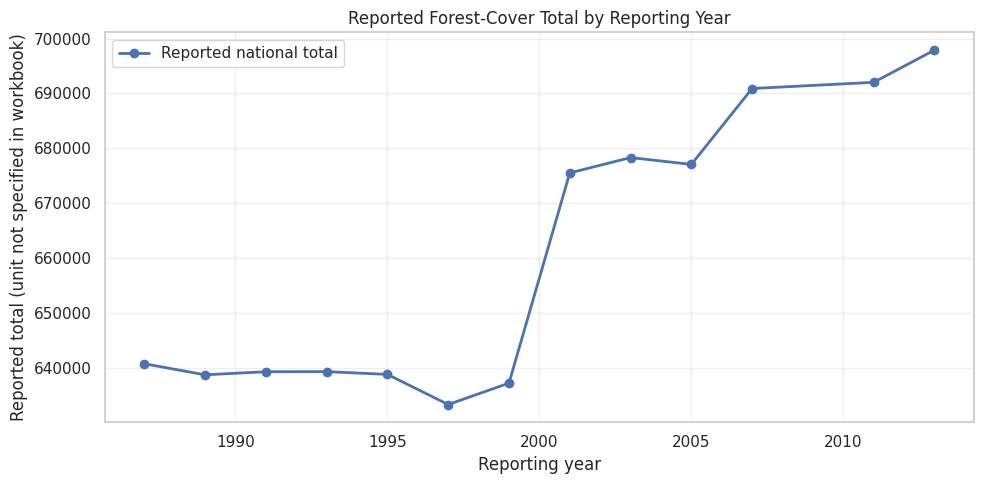

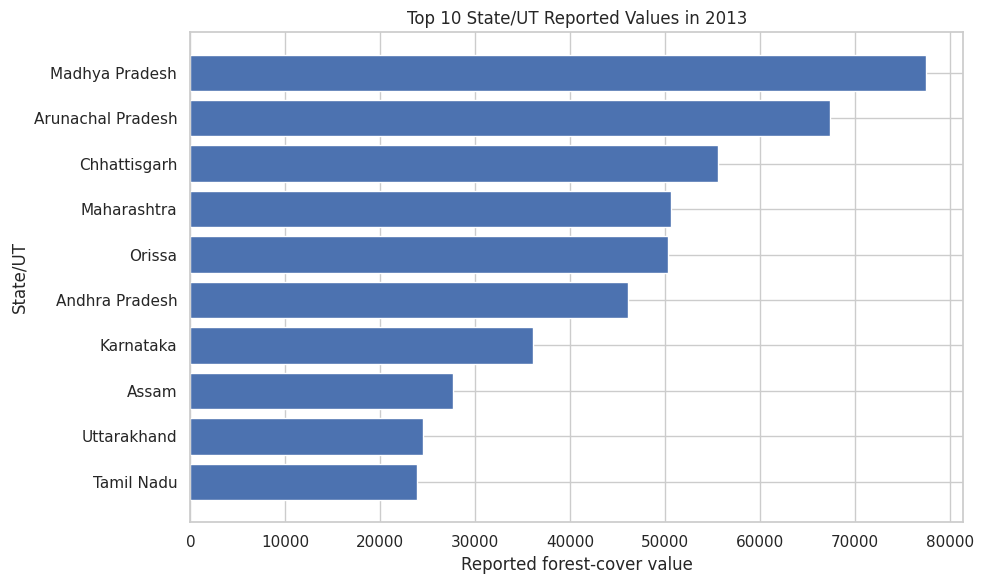

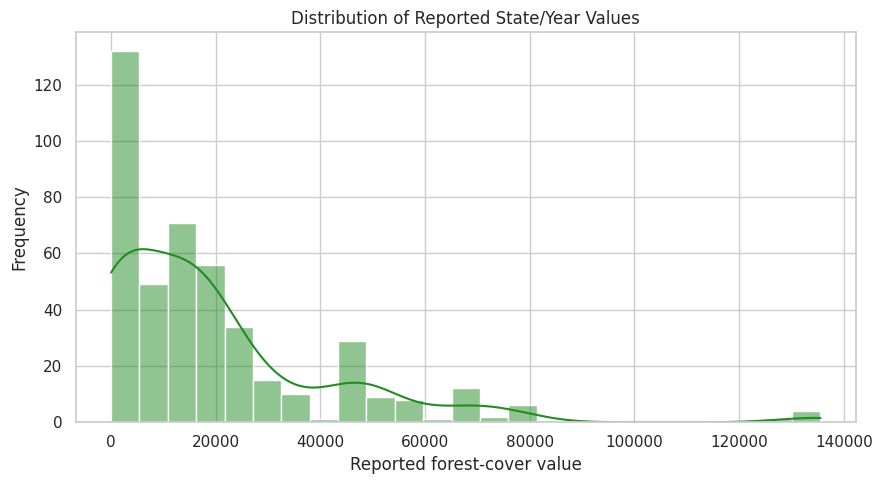

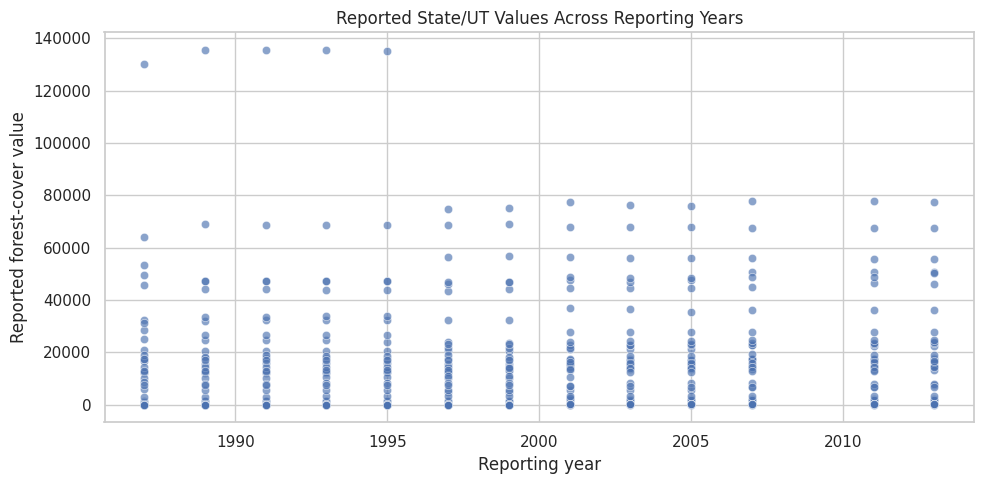

In [ ]:
# Line plot: reported national total from the source summary row.
if not national_total.empty:
    plt.figure(figsize=(10, 5))
    plt.plot(national_total.index, national_total.values, marker="o", linewidth=2,
             label="Reported national total")
    plt.title("Reported Forest-Cover Total by Reporting Year")
    plt.xlabel("Reporting year")
    plt.ylabel("Reported total (unit not specified in workbook)")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Bar chart: top 10 state/UT values in latest year.
top_latest = latest.sort_values("Forest_Cover", ascending=False).head(10).sort_values("Forest_Cover")
plt.figure(figsize=(10, 6))
plt.barh(top_latest["State"], top_latest["Forest_Cover"])
plt.title(f"Top 10 State/UT Reported Values in {latest_year}")
plt.xlabel("Reported forest-cover value")
plt.ylabel("State/UT")
plt.tight_layout()
plt.show()

# Histogram
plt.figure(figsize=(9, 5))
sns.histplot(data=long_data, x="forest_cover", bins=25, kde=True, color="forestgreen")
plt.title("Distribution of Reported State/Year Values")
plt.xlabel("Reported forest-cover value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Scatter plot: year versus forest cover for all available state-year records.
plt.figure(figsize=(10, 5))
sns.scatterplot(data=long_data.dropna(subset=["forest_cover"]), x="year", y="forest_cover", alpha=0.65)
plt.title("Reported State/UT Values Across Reporting Years")
plt.xlabel("Reporting year")
plt.ylabel("Reported forest-cover value")
plt.tight_layout()
plt.show()

## 14. Seaborn Graphs

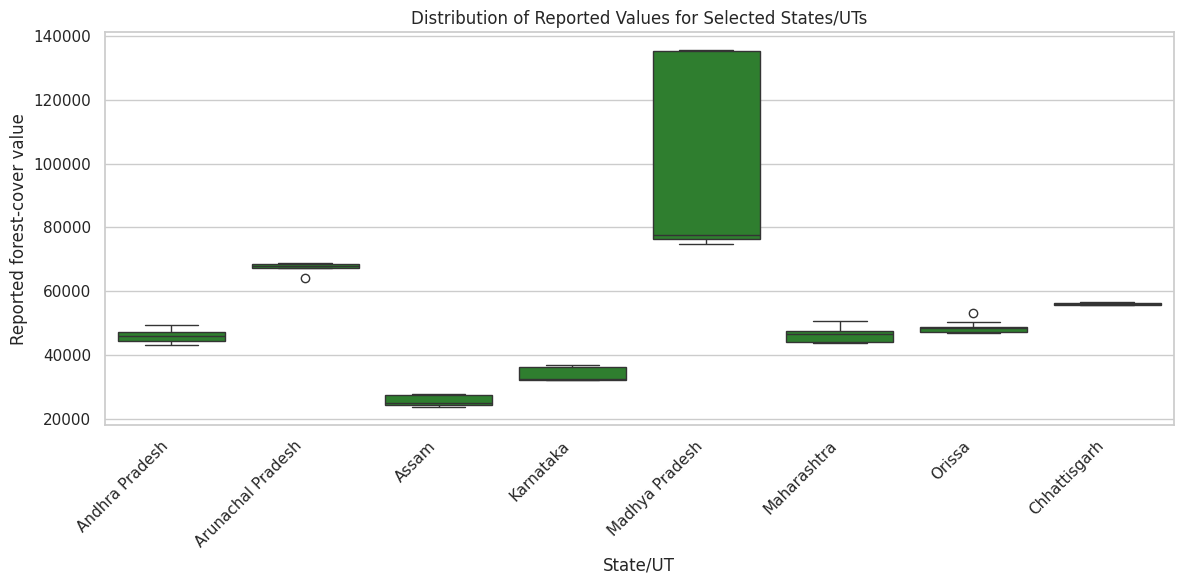

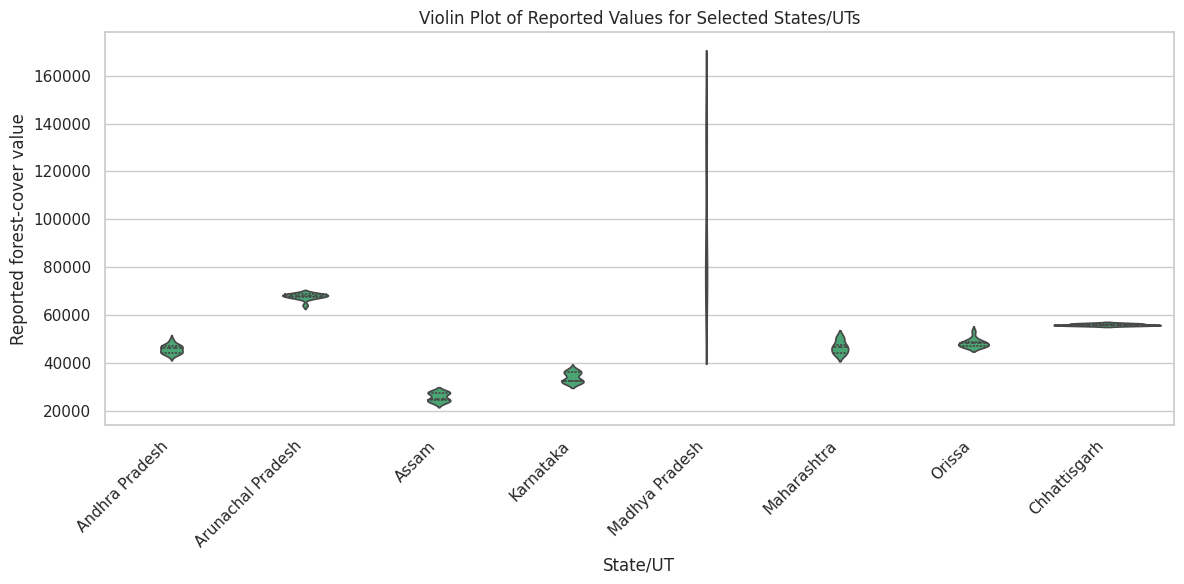

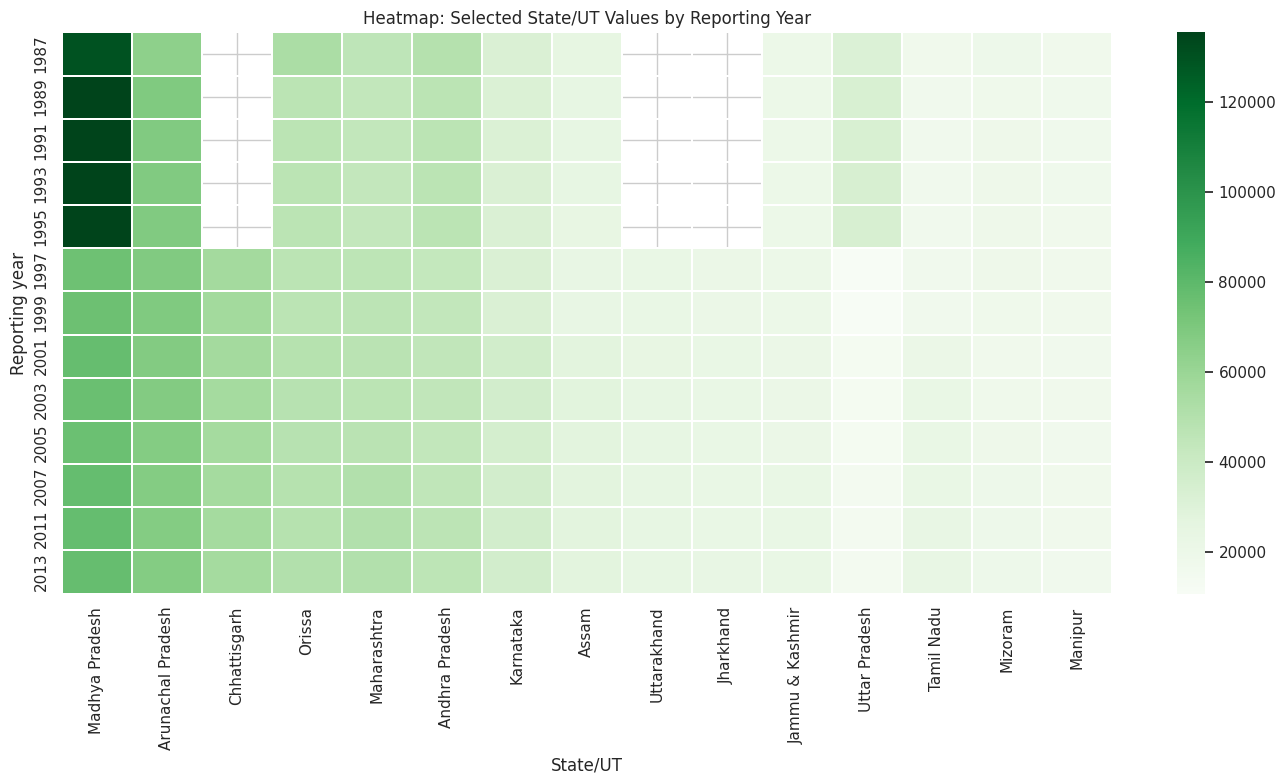

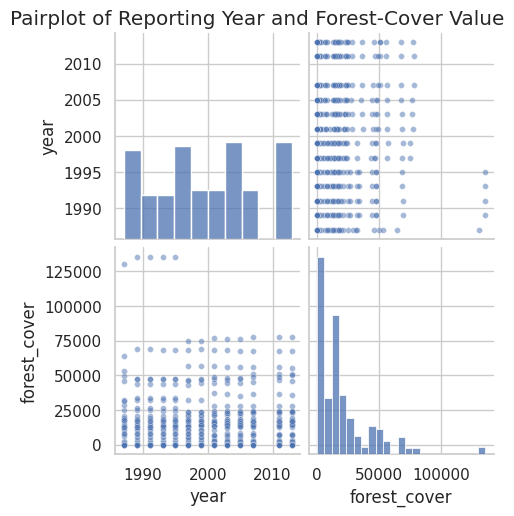

In [ ]:
# Compare distributions for the 8 states/UTs with the highest mean reported values.
top_states = state_summary.head(8).index.tolist()
plot_data = long_data[long_data["state"].isin(top_states)].dropna(subset=["forest_cover"]).copy()

plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_data, x="state", y="forest_cover", color="forestgreen")
plt.title("Distribution of Reported Values for Selected States/UTs")
plt.xlabel("State/UT")
plt.ylabel("Reported forest-cover value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.violinplot(data=plot_data, x="state", y="forest_cover", color="mediumseagreen", inner="quartile")
plt.title("Violin Plot of Reported Values for Selected States/UTs")
plt.xlabel("State/UT")
plt.ylabel("Reported forest-cover value")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Heatmap: selected states across all reporting years.
heat_states = state_summary.head(15).index.tolist()
heatmap_data = pivot_data.reindex(columns=heat_states).astype(float)
plt.figure(figsize=(14, 8))
sns.heatmap(heatmap_data, cmap="Greens", linewidths=0.2)
plt.title("Heatmap: Selected State/UT Values by Reporting Year")
plt.xlabel("State/UT")
plt.ylabel("Reporting year")
plt.tight_layout()
plt.show()

# Pairplot on a reproducible sample, with two numeric variables.
pair_data = long_data[["year", "forest_cover"]].dropna()
if len(pair_data) > 500:
    pair_data = pair_data.sample(500, random_state=42)
sns.pairplot(pair_data, diag_kind="hist", plot_kws={"alpha": 0.5, "s": 18})
plt.suptitle("Pairplot of Reporting Year and Forest-Cover Value", y=1.02)
plt.show()

## 15. Forest Cover Map (Optional)

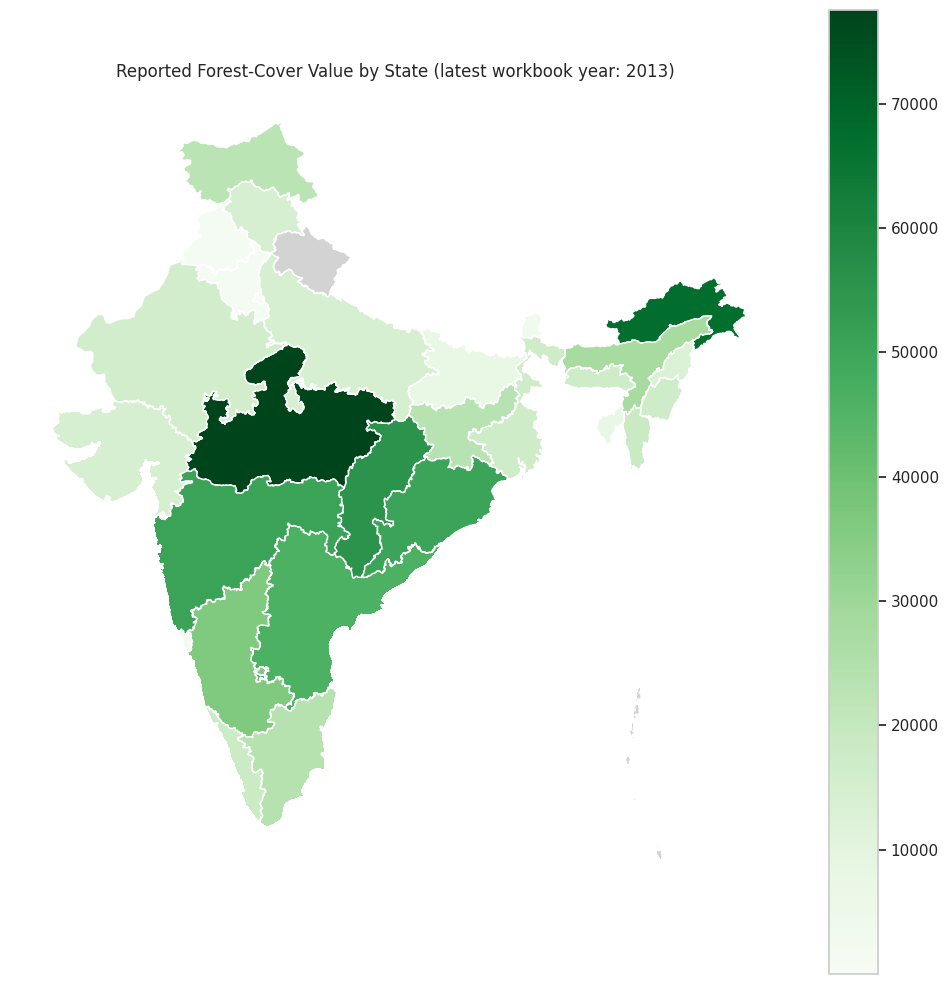

Map created. Grey regions indicate no matched value, not zero forest cover.


In [ ]:
# Optional map. If the map boundary source or package is unavailable, the rest of the project still works.
try:
    import geopandas as gpd

    geojson_url = "https://raw.githubusercontent.com/geohacker/india/master/state/india_state.geojson"
    india_map = gpd.read_file(geojson_url)

    # Detect the state-name field in common GeoJSON versions.
    candidates = ["st_nm", "NAME_1", "name", "STATE"]
    geo_name_col = next((c for c in candidates if c in india_map.columns), None)
    if geo_name_col is None:
        raise ValueError(f"Could not find state-name column. Available: {india_map.columns.tolist()}")

    map_values = latest[["State", "Forest_Cover"]].copy()

    def norm_state(s):
        s = str(s).strip().casefold()
        s = s.replace("&", "and")
        s = re.sub(r"[^a-z0-9]+", " ", s)
        return re.sub(r"\s+", " ", s).strip()

    # Align a few known historical labels with common map labels.
    aliases = {
        "orissa": "odisha",
        "a n islands": "andaman and nicobar islands",
        "andaman nicobar islands": "andaman and nicobar islands",
        "dadra nagar haveli": "dadra and nagar haveli",
        "daman diu": "daman and diu",
    }
    map_values["join_key"] = map_values["State"].map(norm_state).replace(aliases)
    india_map["join_key"] = india_map[geo_name_col].map(norm_state).replace(aliases)

    joined_map = india_map.merge(map_values[["join_key", "Forest_Cover"]], on="join_key", how="left")

    ax = joined_map.plot(
        column="Forest_Cover", cmap="Greens", legend=True,
        figsize=(10, 10), missing_kwds={"color": "lightgrey", "label": "No matched value"}
    )
    ax.set_title(f"Reported Forest-Cover Value by State (latest workbook year: {latest_year})")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

    print("Map created. Grey regions indicate no matched value, not zero forest cover.")
except Exception as e:
    print("Optional map could not be created in this environment.")
    print("Reason:", repr(e))
    print("The rest of the EDAV analysis is independent of this optional map.")
    print("If needed, upload a state-boundary GeoJSON/shapefile and adapt the join.")

## 16. Results

In [ ]:
# Use source summary rows for national-level figures rather than summing incomplete state rows.
if not national_total.empty:
    first_year, last_year = int(national_total.index.min()), int(national_total.index.max())
    first_total, last_total = float(national_total.loc[first_year]), float(national_total.loc[last_year])
    absolute_change = last_total - first_total
    percent_change = absolute_change / first_total * 100
    print(f"Reported national total: {first_year} = {first_total:,.0f}")
    print(f"Reported national total: {last_year} = {last_total:,.0f}")
    print(f"Absolute change across endpoints: {absolute_change:,.0f}")
    print(f"Percentage change across endpoints: {percent_change:.2f}%")

if not national_percent.empty:
    first_pct, last_pct = float(national_percent.iloc[0]), float(national_percent.iloc[-1])
    print(f"Reported percentage: {first_pct:.2f}% -> {last_pct:.2f}%")
    print(f"Change in percentage points: {last_pct-first_pct:.2f}")

print("\nTop five state/UT values in the latest reporting year:")
display(latest[["State", "Forest_Cover", "Rank"]].head(5))

Reported national total: 1987 = 640,819
Reported national total: 2013 = 697,898
Absolute change across endpoints: 57,079
Percentage change across endpoints: 8.91%
Reported percentage: 19.49% -> 21.23%
Change in percentage points: 1.74

Top five state/UT values in the latest reporting year:


,State,Forest_Cover,Rank
434,Madhya Pradesh,77522.0,1
421,Arunachal Pradesh,67321.0,2
424,Chhattisgarh,55621.0,3
435,Maharashtra,50632.0,4
440,Orissa,50347.0,5
